# Plotting the Results

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/ch4/4C-butadiene/butadiene_plots.ipynb)
:::

We have data from a [previous rotation scan](butadiene.ipynb#rotational-scan-text) for butadiene. Depending on the level of theory and the Z-matrix used, we generated several data files. You may have used different file names, but these are the files in the data folder for this notebook.

``` text
butadiene_scan_HF_631.json
butadiene_scan_B3LYP-D3BJ_631GX.json
butadiene_scan_HF_631-nosym.json
butadiene_scan_B3LYP-D3BJ_631GX-nosym.json
butadiene_scan_HF_631-C2.json
butadiene_scan_B3LYP-D3BJ_631GX-C2.json
```

## Setting up this Notebook

The collapsed [code cell below](#setup-cell-butadiene-plots) will **load in** all the *Python* packages and set global variables for the calculations in this notebook. If you are using *Colab*, **run this cell first**, watch it eventually crash, and then **run it again** and you will be set up.

In [ ]:
#| label: setup-cell-butadiene-plots
#| tags: [remove-output, hide-input]

####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import json

import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import skimage          # scikit-image draws the static orbital and density surfaces
except ImportError:
    !pip -q install scikit-image
    import skimage

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/S2_classic2.mplstyle
    !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py

# The load data for this notebook
if IN_COLAB and not Path("data/butadiene_scan_B3LYP-D3BJ_631GX-C2.json").exists():
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_HF_631.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_B3LYP-D3BJ_631GX.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_HF_631-nosym.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_B3LYP-D3BJ_631GX-nosym.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_HF_631-C2.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/data/butadiene_scan_B3LYP-D3BJ_631GX-C2.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/butadiene_scan_B3LYP-D3BJ_631GX-C2v-to-C2h.json
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch4/4C-butadiene/butadiene_scan_HF_631-C2v-to-C2h.json

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    sys.path.insert(0, "../..")                 # psi4_helpers.py is two folders up
    plt.style.use("../../styles/tufte.mplstyle")

import psi4_helpers as ph

# Psi4 output (.out, .log, .molden, cube files, scans) goes into output/, which is not kept in git.
# Small results files that another page reads (.json, .csv) go into data/, which is kept in git.
output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)
data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = True

(json-to-plots-butadiene1)=
## Get the Data

We will **load** in data from **previous** rotational scans. We will take a list of file names from saved calculation results and import each file one-by-one. Each file will **recreate** the data dictionary produced in the [previous notebook](butadiene.ipynb#rotational-scan-text) and will be **assigned** to a named item in the larger dictionary named `data`.

The keys in the `data` dictionary object, the filenames from which that each was loaded, and a description of the calculation that produced that each file are given below.


```{list-table} Keys, filenames and description of each calculation contained in the data object..
:label: tbl-name-butadiene
:header-rows: 1

* - Key
  - File name
  - Description
* - HF
  - butadiene_scan_HF_631.json
  - Relaxed scan starting in $C_{2v}$ using a low-effort method. 
* - B3LYP
  - butadiene_scan_B3LYP-D3BJ_631GX.json
  - Same as above using a medium-effort method.
* - HF_C1
  - butadiene_scan_HF_631-nosym.json
  - Relaxed scan starting in $C_{1}$ with no symmetry required using a low-effort method. Used a Z-matrix where none of the variables were paired.
* - B3LYP_C1
  - butadiene_scan_B3LYP-D3BJ_631GX-nosym.json
  - Same as above using a medium-effort method.
* - HF_C2
  - butadiene_scan_HF_631-C2.json
  - Relaxed scan starting in $C_{2}$ with $C_2$ symmetry required using a low-effort method.
* - B3LYP_C2
  - butadiene_scan_B3LYP-D3BJ_631GX-C2.json
  - Same as above using a medium-effort method.
* - HF_C2v_C2h
  - butadiene_scan_HF_631-C2v-to-C2h.json
  - Scan starting in $C_{2n}$ with $C_2$ symmetry required. Reusing same Z-matrix with perfectlt flat geometry in each step of scan. Uses a low-effort method.
* - B3LYP_C2v_C2h
  - butadiene_scan_B3LYP-D3BJ_631GX-C2v-to-C2h.json
  - Same as above using a medium-effort method.
```

The [following code](#load-in-results-to-data-object) will load in the *json* files and use them to **construct** a data object that holds all the data from **previous** calculations. 

In [ ]:
#| label: load-in-results-to-data-object
#| class: scroll-input

# list of file names
names = ["butadiene_scan_HF_631.json",
         "butadiene_scan_B3LYP-D3BJ_631GX.json",           
         "butadiene_scan_HF_631-nosym.json",               
         "butadiene_scan_B3LYP-D3BJ_631GX-nosym.json",     
         "butadiene_scan_HF_631-C2.json",                  
         "butadiene_scan_B3LYP-D3BJ_631GX-C2.json",        
         "butadiene_scan_HF_631-C2v-to-C2h.json",          
         "butadiene_scan_B3LYP-D3BJ_631GX-C2v-to-C2h.json"
        ]

# corresponding list of names for each data dictionary entry
dict_names = ["HF", "B3LYP", 
              "HF_C1", "B3LYP_C1", 
              "HF_C2", "B3LYP_C2", 
              "HF_C2v_C2h", "B3LYP_C2v_C2h"
              ]

# make a very large data object using all the data files so that I don't
# need to reload any data as I go through this notebook

data_dir = Path("data")

data = {} # create empty data object
for name, dict_name in zip(names, dict_names):
    # recreate the result object from the json file
    with open(data_dir / name) as f:
        scan = json.load(f)            # load data into the object named 'scan'
    data[dict_name] = scan
 


### Check the Data

We will **access** the data that started with a perfectly flat $C_{2v}$ structure of butadiene and performed a relaxed scan of the dihedral angle, `D`, from `D - 0` to `D = 180`. That data set is **named** `HF` in the `data` object. Inspecting the keys in `data`, we see that `HF` is in position `0` of the list. We can **check** each set of results in the data object by **changing** the value of `n` in the [code below](#check-dict-object).


In [48]:
#| label: check-dict-object

# n = 1 # change n to check each imported data set in the data dictionary.
keys = list(data.keys())
# print the names of entries in the data dictionary
print(f"List of dictionaries has been imported. ")
print("Names of each data set in the data dictionary")
print(keys, "\n")
# print out the labels for the contents of the loaded data object
print(f"Keys in the {keys[n]} dictionary are... ")
print(list(data[keys[n]][0].keys()), "\n")
print("Keys in 'var' dictionary are... ")
print(list(data[keys[n]][0]["var"].keys()))


List of dictionaries has been imported. 
Names of each data set in the data dictionary
['HF', 'B3LYP', 'HF_C1', 'B3LYP_C1', 'HF_C2', 'B3LYP_C2', 'HF_C2v_C2h', 'B3LYP_C2v_C2h'] 

Keys in the B3LYP dictionary are... 
['D', 'E', 'steps', 'E_homo', 'E_lumo', 'sym', 'PG', 'xyz', 'Z', 'var'] 

Keys in 'var' dictionary are... 
['D', 'aCCC', 'aHCCcent', 'aHCCendo', 'aHCHterm', 'rCCcent', 'rCCterm', 'rCHcent', 'rCHtermen', 'rCHtermex', 'tHCCCcent', 'tHCCCendo', 'tHCHC']


Now we have the data and can **start playing** with it.
## Observations

We can **investigate** the data and make some initial **observations**. 

### Symmetry

I expect that the **first calculation**, that **started** as $C_{2v}$, would remain **locked** in that **symmetry**. Subsequent optimizations would by definition begin with $C_2$ structures. But, would the final optimization at `D = 180`, **find** the **perfectly flat** $D_{2h}$ structure. I **hypothesize** that it will not because it will be starting with the `D = 175` structure, in which the double bond torsions are **not exactly** 0° and 180°. After the `mol.set_variable("D", 180)` method was applied to the molecule object, we have `D = 180`, but **not the** original **perfect** values for the other torsions.

The [code below](#check_sym_list) will check each result for the symmetry detected by *Psi4*. $C_2$ symmetry is enforced by the way the Z-matrix and variables [were set up](butadiene.ipynb#butadiene-zmatrix-perfect). We see the [same output](butadiene.ipynb#results-c2v-to-c2h-sym) as from when this result was created in the previous notebook. looks good so far.

In [52]:
#| label: check_sym_list

scan = data["HF_C2v_C2h"]  # choose this scan result
D_list = [item["D"] for item in scan]     # make a list of value of D for each step in scan
sym_list = [item["PG"] for item in scan]  # make a list of symmetry designations for each setp of scan

middle = int(len(D_list)/2)
# print first and last item in list as well as one item from in the middle
print(f"first entry in list is: {sym_list[0]}, for D = {D_list[0]}")
print(f"entry in position {middle} is: {sym_list[middle]}, for D = {D_list[middle]}")
print(f"final entry in list is: {sym_list[-1]}, for D = {D_list[-1]}") # "-1" means the last item in a list

first entry in list is: C2v, for D = 0.0
entry in position 18 is: C2, for D = 90.0
final entry in list is: C2h, for D = 180.0


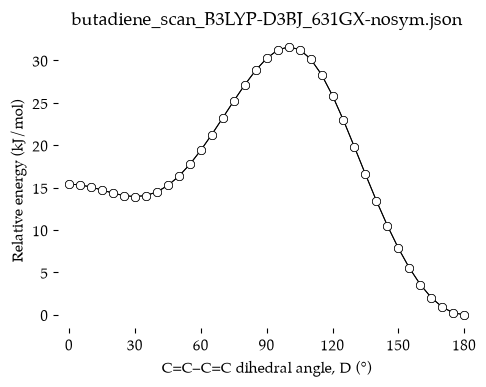

In [38]:
plt.style.use("../../styles/tufte.mplstyle")
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))


scan.sort(key=lambda point: point["D"])          # make sure points are in order of D
Ds = [point["D"] for point in scan]
Es = [point["E"] for point in scan]              # hartree
E_min = min(Es)
E_rel = [(E - E_min) * 2625.5 for E in Es]       # kJ/mol relative to the lowest point

ax.plot(Ds, E_rel, color="black", linewidth=0.7, 
        marker="o", markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=0.5, 
        zorder=2)

scan2.sort(key=lambda point: point["D"])          # make sure points are in order of D
Ds = [point["D"] for point in scan2]
Es = [point["E"] for point in scan2]              # hartree
E_min = min(Es)
E_rel = [(E - E_min) * 2625.5 for E in Es]       # kJ/mol relative to the lowest point

ax.plot(Ds, E_rel, color="black", linewidth=0.7, 
        marker="o", markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=0.5, 
        zorder=2)


ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("Relative energy (kJ/mol)")
ax.set_xlim(-5, 185)
ax.set_xticks([0,30,60,90,120,150,180])
ax.set_title(name)

plt.show()

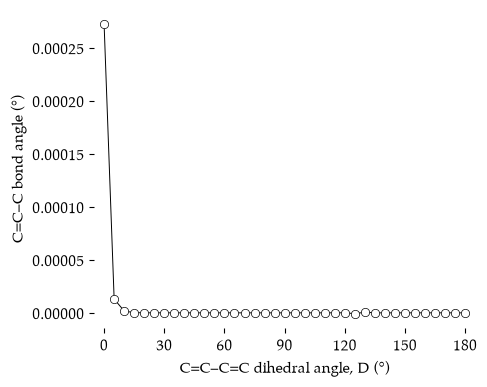

In [47]:
diff_var1 = "rCCterm"
diff_var2 = "rCCtermB"
Ds = [point["D"] for point in scan] 
As = np.array([point["var"][diff_var1] for point in scan]) \
      - np.array([point["var"][diff_var2] for point in scan2])          

plt.style.use("../../styles/tufte.mplstyle")
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
ax.plot(Ds, As, 
        color="black", linewidth=0.7, 
        linestyle="-", marker="o", markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=0.5, 
        zorder=2)

ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("C=C–C bond angle (°)")
ax.set_xlim(-5, 185)
ax.set_xticks([0,30,60,90,120,150,180])
#ax.set_ylim(123.9, 127.3)
#ax.set_yticks([124,125,126,127])

plt.show()

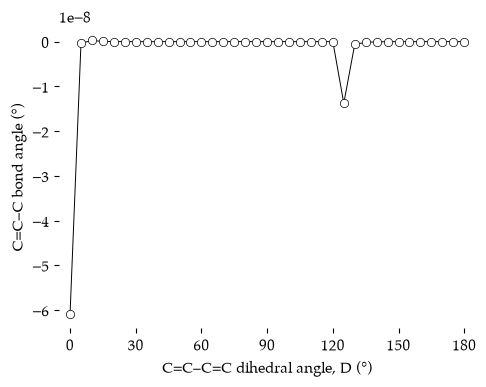

In [48]:
plt.style.use("../../styles/tufte.mplstyle")
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))


diff_var1 = "rCCterm"
diff_var2 = "rCCtermB"
Ds = [point["D"] for point in scan] 
As = np.array([point["E"] for point in scan]) \
      - np.array([point2["E"] for point2 in scan2])  

ax.plot(Ds, As, 
        color="black", linewidth=0.7, 
        linestyle="-", marker="o", markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=0.5, 
        zorder=1)

ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("C=C–C bond angle (°)")
ax.set_xlim(-5, 185)
ax.set_xticks([0,30,60,90,120,150,180])
#ax.set_ylim(123.9, 127.3)
#ax.set_yticks([124,125,126,127])

plt.show()

In [44]:
scan[0]["E"]-scan2[0]["E"]

-6.099455163166567e-08

In [ ]:
#name = "butadiene_scan_HF_631.json"
#name = "butadiene_scan_B3LYP-D3BJ_631GX.json"
#name = "butadiene_scan_HF_631-nosym.json"
name = "butadiene_scan_B3LYP-D3BJ_631GX-nosym.json"

# recreate the result object from the json file
data_dir = Path("data")
with open(data_dir / name) as f:
    scan2 = json.load(f)            # load data into the object named 'scan'

# print out the labels for the contents of the loaded data object
print("List of dictionaries has been imported. Keys in each dictionay are... ")
print(list(scan2[0].keys()))
print("Keys in 'var' dictionay are... ")
print(list(scan2[0]["var"].keys()))
